# 09 ema200 touch

Validation backtest for this trading module. The tape is synthetic and seeded, so the chart checks that the production rules fire and how the book compounds after 10 bps a side. It is not a live-edge claim.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.validation.figures import draw_module, metrics_frame
from pipeline.research.validation.modules import run_module
from pipeline.research.validation.panel import synthetic_panel

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)


In [2]:
panel = synthetic_panel()
result = run_module('ema200', panel)
print(result.title)
for rule in result.rules:
    print("-", rule)
print()
print(result.note)
metrics_frame(result)


EMA200 touch bounce
- Long when price has stayed above a rising EMA200 and the low tags the EMA within 0.25 ATR.
- The close must hold the EMA. A close under it is a breakdown, not a buy.
- Exit on an ATR stop, a close back under the EMA, or the research time stop.
- History floor in this notebook is 220 bars so the synthetic tape can show the rule. Production warmup is longer.

Synthetic tape, seeded. Paper costs of 10 bps a side. Not a live-edge claim.


,days,total_return_pct,cagr_pct,sharpe,max_drawdown_pct,n_trades,win_rate_pct,avg_trade_pct
0,420,0.03,0.02,0.06,-0.33,4,0.0,-1.325


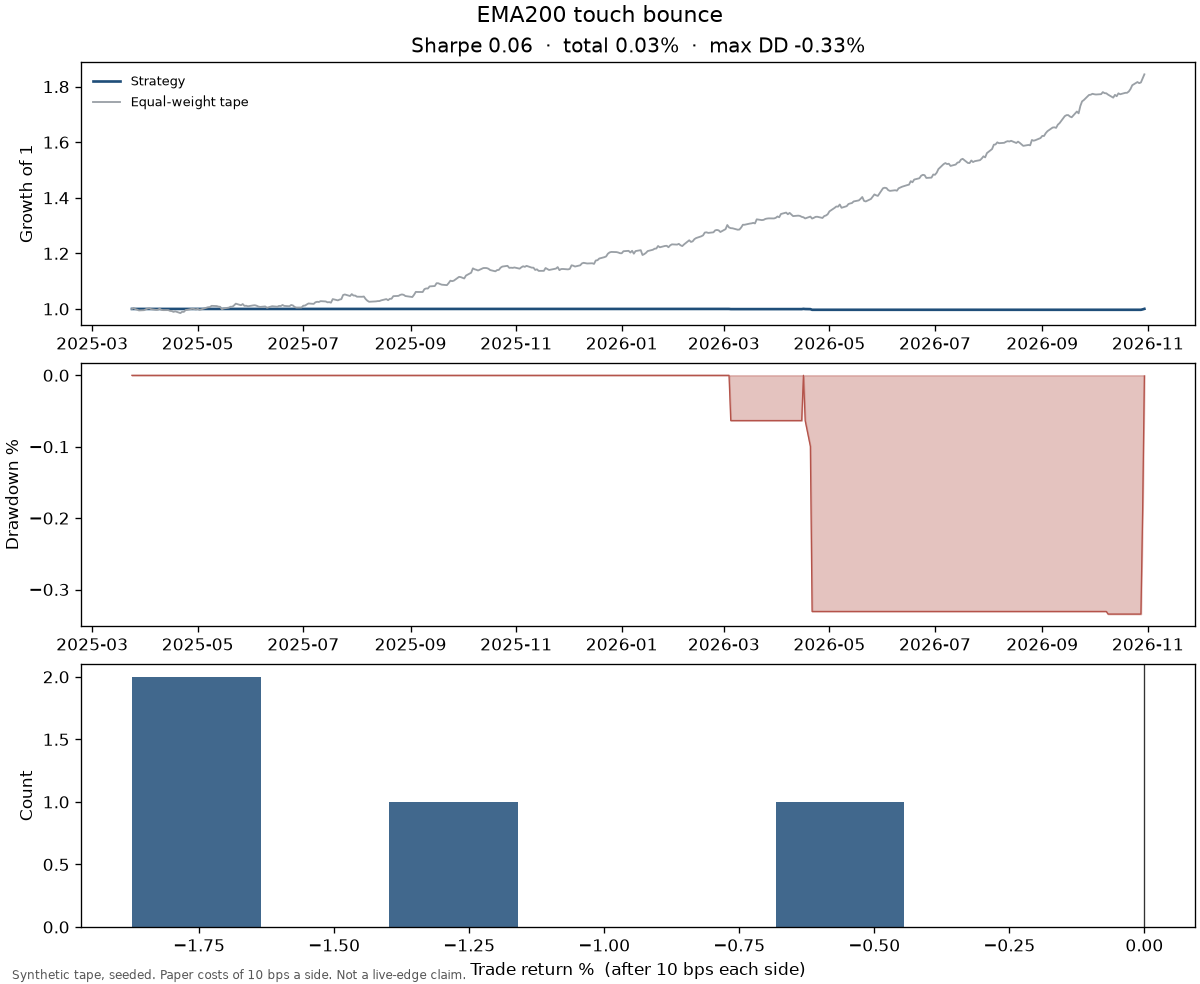

In [3]:
from IPython.display import Image, display

fig_dir = ROOT / "pipeline" / "research" / "notebooks" / "validation" / "figures"
fig_path = fig_dir / "09_ema200_touch.png"
fig = draw_module(result, fig_path)
plt.close(fig)
display(Image(filename=str(fig_path)))
